# 08 SRC Ablation and Robustness

**Scientific question.** What is attributable to physics, capacity, and correction?

**Learning objectives.** Compare controlled ablations and distinguish prediction from angle stress.

**Prerequisites.** Install the project requirements. Configure the data directory for raw-record checks. Portable evidence review also uses the existing run artifacts.

**Dataset and run.** Course gearbox at 3.2 kHz, the project’s designated training and held-out development records, and the explicit diagnostic or blind availability files where relevant.

**Execution.** This clean-kernel replay reads the evidence cited in each code cell. Use the explicit project pipeline for full fitting and the notebook build script for review replay. The companion guide contains notation, figures, and worked examples.

In [1]:
import hashlib
import json
import os
from pathlib import Path
import platform
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
get_ipython().run_line_magic("matplotlib", "inline")
from IPython.display import Image, display

hint = os.environ.get("SRC_PROJECT_DIR")
locations = [Path(hint).resolve()] if hint else [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in locations if (p / "src" / "src_gearbox").is_dir()), None)
if ROOT is None:
    raise RuntimeError("Open within the project or set SRC_PROJECT_DIR.")
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
DATA = Path(os.environ.get("SRC_DATA_DIR", ROOT / "data" / "raw"))
RESULTS = ROOT / "results"
START = 1792
N = 24000
pd.options.display.max_colwidth = 120
pd.options.display.width = 115
plt.rcParams.update({"figure.dpi": 105, "axes.grid": True, "grid.alpha": .18})

def table(relative):
    file = ROOT / relative
    if not file.is_file():
        print(f"NOT AVAILABLE YET · {relative}")
        return None
    return pd.read_csv(file)

def evidence(relative):
    file = ROOT / relative
    if not file.is_file():
        print(f"NOT AVAILABLE YET · {relative}")
        return {}
    return json.loads(file.read_text(encoding="utf-8"))

def show_fig(relative, width=780):
    file = ROOT / relative
    if file.is_file():
        display(Image(filename=str(file), width=width))
    else:
        print(f"NOT AVAILABLE YET · {relative}")

def forecast(relative):
    file = ROOT / relative
    if not file.is_file():
        print(f"NOT AVAILABLE YET · {relative}")
        return {}
    with np.load(file, allow_pickle=False) as source:
        arrays = {key: source[key] for key in source.files}
    np.testing.assert_array_equal(arrays["target_indices"], np.arange(START, N))
    assert np.isfinite(arrays["actual"]).all()
    return arrays

def align_forecasts(reference, *others):
    for other in others:
        for key in ("target_indices", "actual", "rpm", "time_s"):
            np.testing.assert_array_equal(reference[key], other[key])

def draw_forecast(bundle, keys, view=slice(5000, 5200)):
    if not bundle:
        return
    y, t = bundle["actual"], bundle["time_s"]
    fig, ax = plt.subplots(2, 1, figsize=(9.0, 4.0), sharex=True, layout="constrained")
    ax[0].plot(t[view], y[view], color="#141a26", lw=1.2, label="Measured")
    for key, label in keys.items():
        if key in bundle:
            pred = bundle[key]
            ax[0].plot(t[view], pred[view], lw=0.9, label=label)
            ax[1].plot(t[view], (y-pred)[view], lw=0.9, label=label)
    ax[0].legend(ncol=3, fontsize=8)
    ax[0].set_ylabel("Std. vibration")
    ax[1].set(ylabel="Std. residual", xlabel="Acquisition time (s)")
    plt.show()

print("Read-only evidence replay.", f"Python {platform.python_version()}",
      f"NumPy {np.__version__}. One-step observed history through t−1.")

Read-only evidence replay. Python 3.12.14 NumPy 2.5.5. One-step observed history through t−1.


### Separate representation, correction, and robustness

A feature-group ablation generally refits the readout with that group
removed. Mutating a feature only at inference is a stress intervention.
A same-weight adapter-off comparison isolates the runtime correction. A
matched adapter on polynomial SRC and the sparse LPV control determines
whether earlier errors create a generic advantage independent of
optimized physical states.

Perturb RPM in the predictor and in the diagnostic angle axis separately.
Add a repeatable synthetic pulse pattern into the measured history, then
compare the changes in residual and pulse geometry. These are controlled
responses, with a limited connection to physical crack severity.

,model,display,mse,mae,train_mse,feature_columns,history,parameters,warm_median_ms
22,pi_src_order12,pi src order12,0.324770,0.452748,0.302824,1023,1280,1600,374.492856
1,pi_src_pure_mse,PI-SRC (clean-MSE selection),0.326401,0.454074,0.304222,879,1536,1456,497.815910
21,pi_src_order6,pi src order6,0.327042,0.454400,0.305601,915,1280,1492,331.156479
17,pi_src_no_augmentation,pi src no augmentation,0.327177,0.454257,0.304165,879,1280,1456,293.577435
16,pi_src_no_acceleration,pi src no acceleration,0.328697,0.455615,0.308792,878,1280,1455,276.195456
0,primary_pi_src,PI-SRC (selected),0.329973,0.456412,0.308688,879,1280,1456,484.886787
11,pi_src_adapter_on,pi src adapter on,0.329973,0.456412,0.308688,879,1280,1456,487.198193
19,pi_src_high_capacity,pi src high capacity,0.330022,0.456469,0.308593,881,1280,1458,470.173527
18,pi_src_low_capacity,pi src low capacity,0.330144,0.456577,0.309334,849,1280,1426,402.229283
20,pi_src_degree2,pi src degree2,0.330390,0.456753,0.309116,866,1280,1443,388.722545


,model,scenarios,successful,clean_mse,mean_stress_mse,worst_stress_mse,worst_relative_mse,median_delta_pmi,failure_rate,worst_condition
0,sparse_lpv_arma,8,8,0.371406,1.166840,6.554814,17.648670,0.002192,0.0,bias_plus_2pct
1,archived_src_corrected,8,8,0.317788,0.357068,0.454057,1.428805,0.003048,0.0,bias_plus_2pct
2,cnn,8,8,0.394638,0.398226,0.412020,1.044046,-0.000192,0.0,bias_minus_2pct
3,ridge,8,8,0.368059,0.386563,0.433301,1.177261,0.003099,0.0,bias_plus_2pct
4,primary_pi_src,8,8,0.329973,0.370305,0.457031,1.385055,0.000756,0.0,bias_plus_2pct
5,pi_src_adapter_off,8,8,0.340706,0.380924,0.468232,1.374298,0.000355,0.0,bias_plus_2pct
6,pi_src_optimized,8,8,0.340706,0.380924,0.468232,1.374298,0.000355,0.0,bias_plus_2pct
7,pi_src_fixed,8,8,0.360530,0.399313,0.495547,1.374495,0.004300,0.0,bias_minus_2pct
8,src_generic,8,8,0.412117,0.416747,0.423677,1.028052,0.000163,0.0,bias_plus_2pct
9,src_polynomial,8,8,0.447872,0.447872,0.447872,1.000000,0.000000,0.0,smooth_profile_warp


,model,kind,cases,positive_delta_count,median_pmi_delta,max_pmi_delta,median_distortion,median_energy_retention,median_pulse_correlation
0,sparse_lpv_arma,periodic,5,4,0.000341,0.001351,0.924487,1.714258,0.683468
1,sparse_lpv_arma,aperiodic,2,0,-0.000237,-0.000160,1.239046,2.313989,0.696234
2,archived_src_corrected,periodic,5,5,0.000713,0.000946,1.330784,1.969668,0.615739
3,archived_src_corrected,aperiodic,2,0,-0.001368,-0.000941,2.641090,3.687042,0.594409
4,cnn,periodic,5,3,0.000098,0.000931,0.965195,1.763594,0.677072
5,cnn,aperiodic,2,0,-0.000528,-0.000368,1.443216,2.484299,0.663128
6,ridge,periodic,5,5,0.000331,0.001232,0.899306,1.804436,0.709118
7,ridge,aperiodic,2,0,-0.000652,-0.000320,1.292683,2.395319,0.693966
8,primary_pi_src,periodic,5,5,0.000422,0.001544,0.945560,1.793733,0.689971
9,primary_pi_src,aperiodic,2,0,-0.001218,-0.000674,1.620711,2.669703,0.659563


,model,uncorrected_mse,matched_correction_mse,gain_mse,gain,tau,correction_memory,clip
0,strict_sparse_lpv_arma,0.371406,0.367992,0.003413,0.5,512.0,768,1.75
1,selected_pi_src,0.340706,0.329973,0.010733,0.5,512.0,768,1.75
2,polynomial_src,0.447872,0.444834,0.003038,0.5,512.0,768,1.75


,train_start,train_stop,hold_start,hold_stop,mse,note
0,0,3008,4800,7200,1.413805,earlier-only refit; never used for selection
1,0,9408,11200,13600,1.110925,earlier-only refit; never used for selection
2,0,16608,18400,20800,0.353668,earlier-only refit; never used for selection


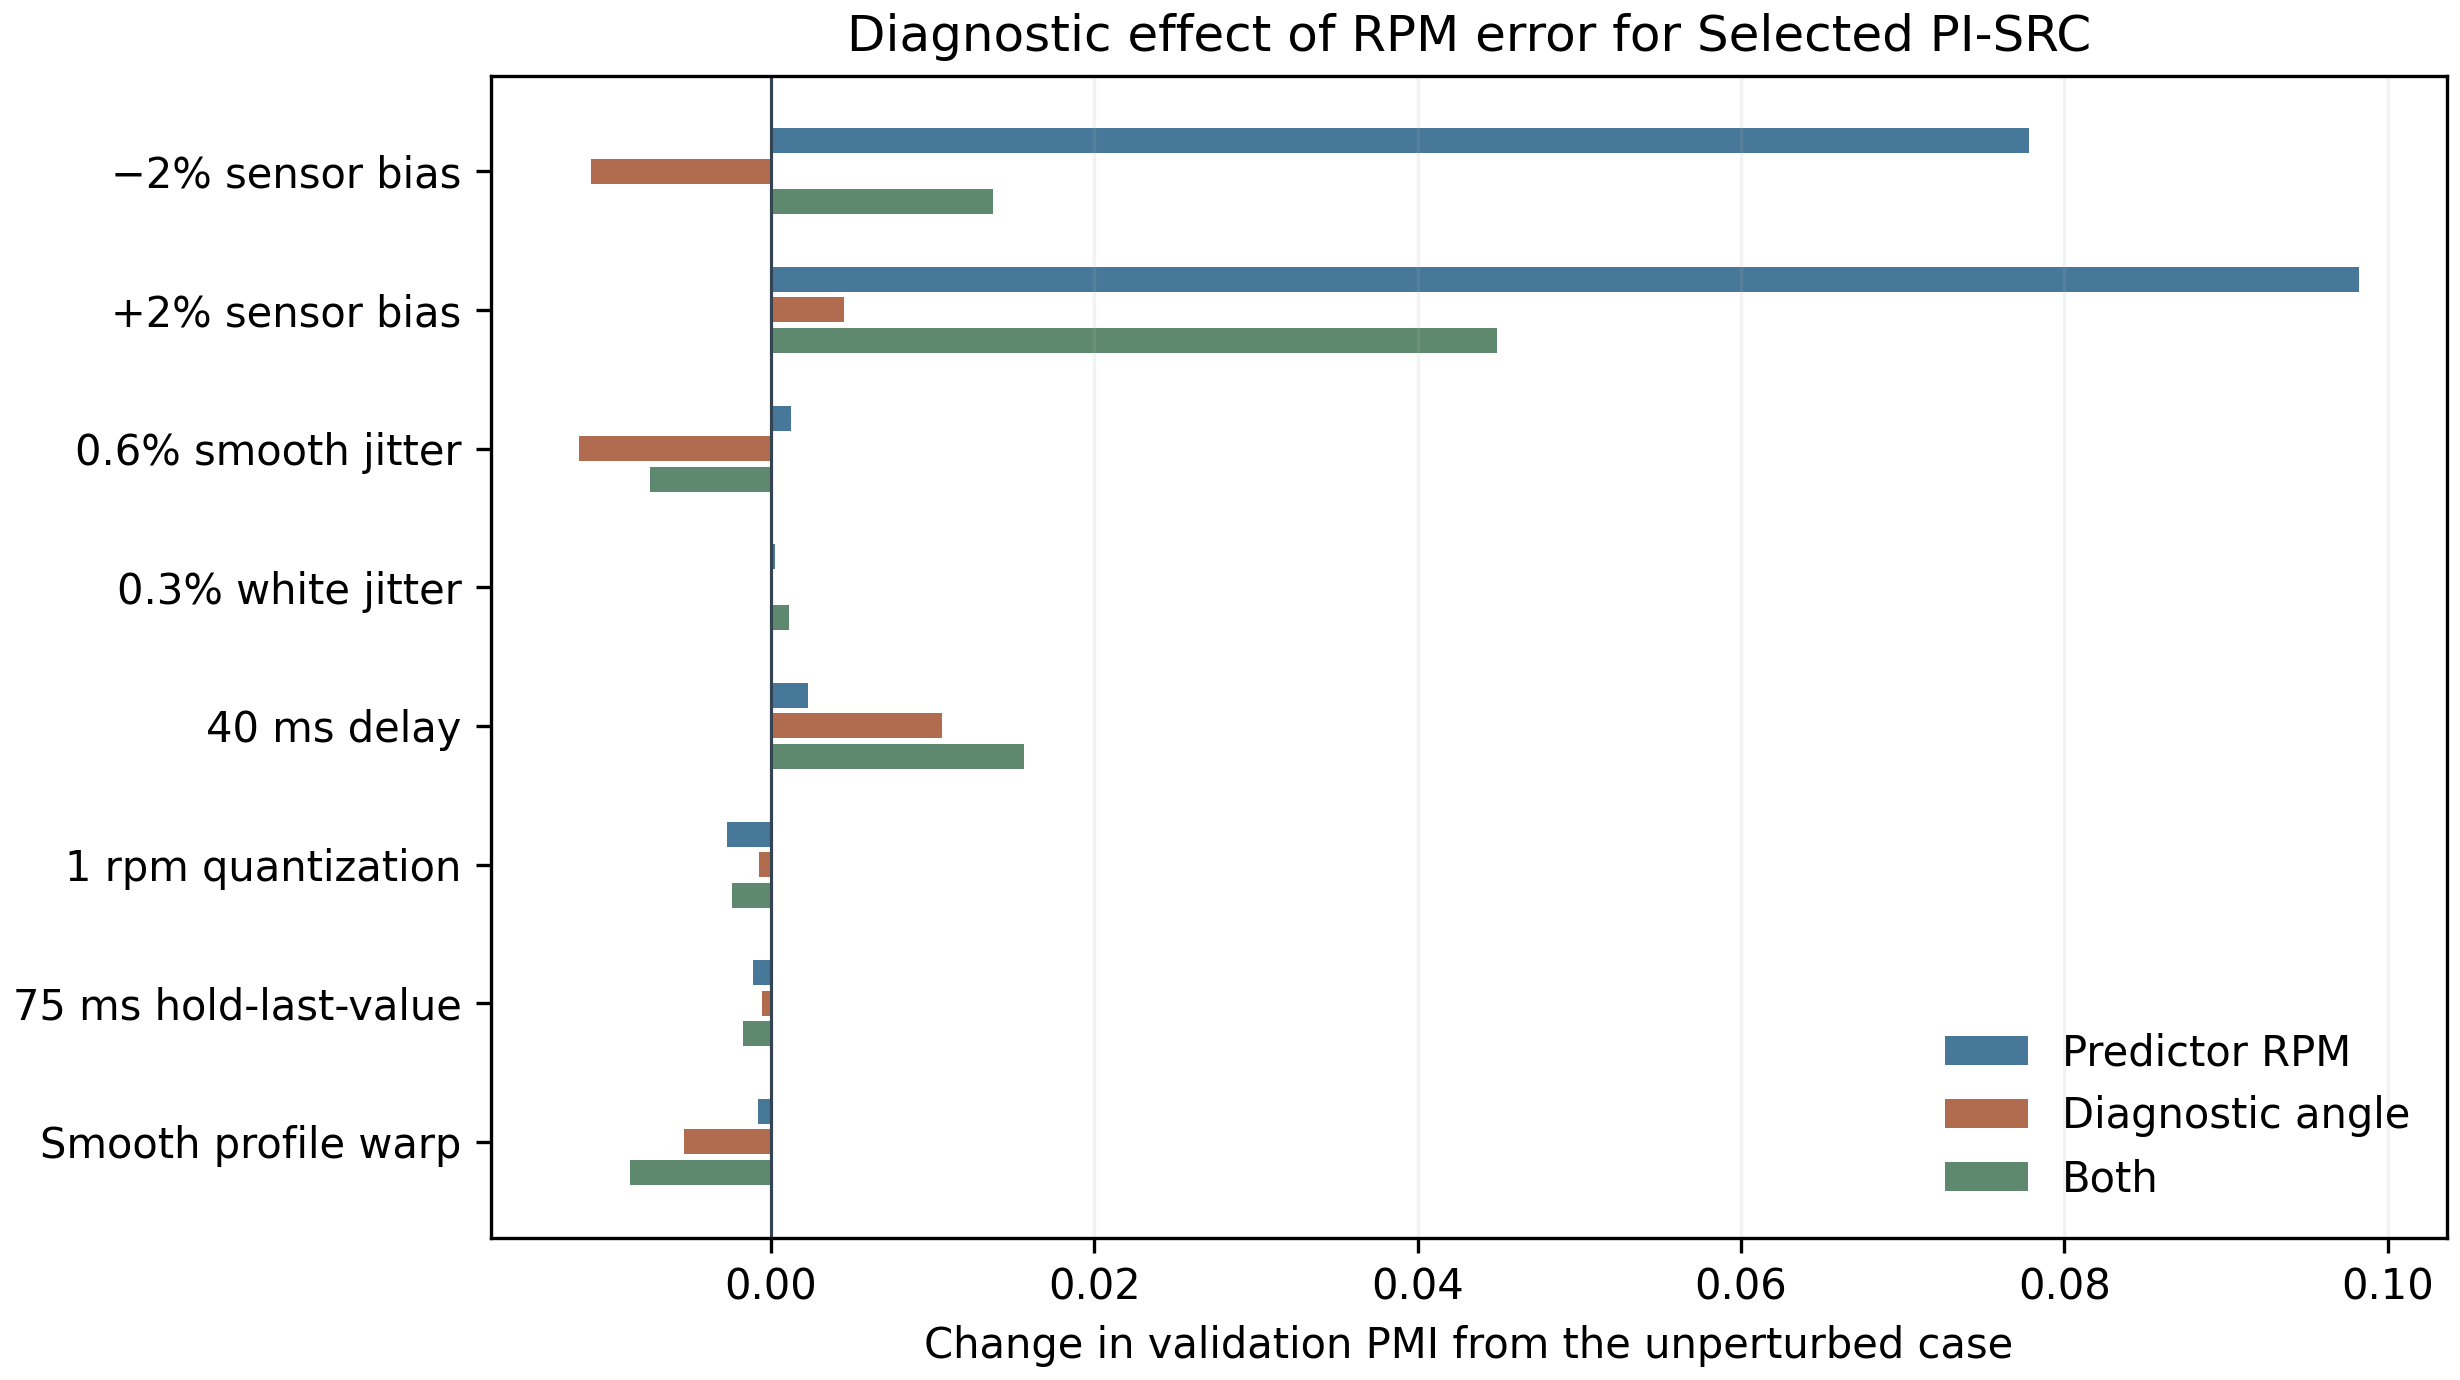

In [2]:
ablated = table("results/ablations/src_ablations.csv")
if ablated is not None:
    wanted = ["model","display","mse","mae","train_mse","feature_columns","history",
              "parameters","warm_median_ms"]
    display(ablated[[k for k in wanted if k in ablated]].sort_values("mse"))
stress = table("results/fault/rpm_stress_summary.csv")
pulses = table("results/fault/pulse_summary.csv")
if stress is not None:
    display(stress.head(12))
if pulses is not None:
    display(pulses.head(12))
matched = table("results/ablations/identical_adapter_controls.csv")
if matched is not None:
    display(matched)
    np.testing.assert_allclose(
        matched.gain_mse, matched.uncorrected_mse-matched.matched_correction_mse)
earlier = table("results/ablations/earlier_only_sensitivity.csv")
if earlier is not None:
    display(earlier)
show_fig("figures/fault/sensor_pmi.png")

In [3]:
candidates = forecast("results/predictions/src_sigvalid.npz")
if candidates:
    clean = candidates["actual"]
    primary_error = (clean-candidates["primary_pi_src"])**2
    comparison = []
    for key, value in candidates.items():
        if key not in {"target_indices","actual","rpm","time_s","primary_pi_src"}:
            comparison.append((key,np.mean((clean-value)**2-primary_error)))
    if comparison:
        display(pd.DataFrame(comparison,columns=["variant","MSE minus primary"]).sort_values("MSE minus primary"))

,variant,MSE minus primary
21,pi_src_order12,-0.005204
0,pi_src_pure_mse,-0.003573
20,pi_src_order6,-0.002931
16,pi_src_no_augmentation,-0.002797
15,pi_src_no_acceleration,-0.001276
10,pi_src_adapter_on,0.000000
18,pi_src_high_capacity,0.000049
17,pi_src_low_capacity,0.000171
19,pi_src_degree2,0.000416
22,pi_src_fixed_hz_only,0.004888


### Interpretation and limits

Interpret mode and score signs before claiming a feature gain. A bundled
change in state width, oscillator bank and penalty only attributes the
result to that complete design. Rotor-angle maps can be more vulnerable
to RPM corruption than simpler fixed-time models. Diagnose the measured
sensitivity before treating the nominal winner as deployment default.

Read the [Companion Guide](../docs/companion_guide.md) and the [Project README](../README.md).